# EDA, Hasil Eksperimen Tugas 2, Analisis Tugas 3

Notebook ini memuat EDA, hasil eksperimen tugas 2, dan analisis tugas 3 berupa studi ablasi yang dapat direproduksi, analisis feature importance, dan distribusi error, yakni sebagai berikut.

**I. Data dan EDA**
1. Preprocessing berita dan kurs
2. Labelling sentimen: **VADER** dan **Loughran-McDonald (LM)**
3. Penyelarasan berita ke hari trading, agregasi harian, serta pembuatan target dan fitur kurs
4. Time-Based Split: **70% train, 15% val, 15% test**
5. **EDA** pada train + val (test disembunyikan)
6. Dataset final
7. Setup modelling: normalisasi (StandardScaler, fit di train saja) dan model dengan **parameter default**

**II. Hasil Eksperimen Tugas 2**
1. **Baseline** (fitur kurs) vs **Baseline + NLP** (fitur kurs + sentimen)
2. Model gabungan + ekstraksi fitur (TF-IDF + SVD)
3. Ringkasan kelompok fitur
4. Ablasi kombinasi label

**III. Analisis Tugas 3** 
1. Studi ablasi Model A/B/C
2. Feature importance
3. Distribusi error dan analisis error


# I. Data dan EDA

## 1. Preprocessing

In [1]:
import re
import html
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from langdetect import detect, DetectorFactory, LangDetectException

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, BayesianRidge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    AdaBoostRegressor,
    GradientBoostingRegressor,
)

SEED = 42
DetectorFactory.seed = SEED
warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)

# Lokasi data (relatif terhadap folder notebook/) dan rentang tanggal yang dipakai di seluruh notebook
RAW_DIR = Path("../data/raw")
PROCESSED_DIR = Path("../data/processed")

START_DATE = pd.Timestamp("2021-09-01")
END_DATE = pd.Timestamp("2026-09-01 23:59:59")

In [2]:
news_raw = pd.read_csv(RAW_DIR / "cnbc_with_published.csv")
bi_raw = pd.read_csv(RAW_DIR / "bi-usd-rate.csv")

print("Berita geopolitik :", news_raw.shape)
print("Kurs USD BI       :", bi_raw.shape)
news_raw.head()

Berita geopolitik : (16733, 13)
Kurs USD BI       : (1202, 5)


,keyword_matched,title,url,preview_summary,full_text,date_raw,section,published_raw,published_date,published_time,published_timezone,published_iso,scrape_status
0,geopolitical risk,Global shipping authorities warn of maritime trade breakdown amidgeopoliticalturmoil,https://www.cnbc.com/2026/09/08/global-shipping-iran-war-hormuz-rules.html?&qsearchterm=geopolitical risk,Global maritime authorities have warned that the emergence of “parallel systems” threatens to create a two-tier stru...,"Global maritime authorities have warned that the emergence of ""parallel systems"" threatens to create a two-tier stru...",9/8/2026 2:28:41 PM,Markets,2026-09-08T07:28:41+0000,2026-09-08,07:28 AM,0.0,2026-09-08T07:28:41+0000,ok
1,geopolitical risk,Morning Call Sheet: AI rebound meets risinggeopoliticalrisks,https://www.cnbc.com/video/2026/07/31/morning-call-sheet-ai-rebound-meets-rising-geopolitical-risks.html?&qsearchter...,"Peter Tchir, Head of Macro Strategy at Academy Securities, Thomas Martin, Senior Portfolio Manager at GLOBALT Invest...",NaN,7/31/2026 5:58:53 PM,Morning Call,NaN,NaN,NaN,NaN,NaN,not_found
2,geopolitical risk,"Global markets keep shrugging off shocks. Here’s what could break that streak, according to HSBC",https://www.cnbc.com/2026/09/08/global-markets-shrug-off-shocks-hsbc-sees-what-could-break-the-streak.html?&qsearcht...,"Global markets have shrugged off a barrage of shocks in recent years, but HSBC sees several developments that could ...","In this article Global markets have shrugged off a barrage of shocks in recent years, but HSBC sees several developm...",9/8/2026 11:02:43 AM,World Markets,2026-09-08T04:02:43+0000,2026-09-08,04:02 AM,0.0,2026-09-08T04:02:43+0000,ok
3,geopolitical risk,"Yen hovers near seven-month high, dollar steadies",https://www.cnbc.com/2026/09/08/yen-extends-rally-to-new-seven-month-high-dollar-subdued-ahead-of-cpi.html?&qsearcht...,"The Japanese yen hovered near ​a seven-month high on Tuesday, while the dollar was little changed against major peer...","In this article The Japanese yen hovered near ​a seven-month high on Tuesday, while the dollar was little changed ag...",9/8/2026 11:17:07 AM,Currencies,2026-09-08T04:17:07+0000,2026-09-08,04:17 AM,0.0,2026-09-08T04:17:07+0000,ok
4,geopolitical risk,Central banks are bringing gold reserves home asgeopoliticalrisks rise,https://www.cnbc.com/2026/06/17/central-banks-gold-reserves-domestic-storage.html?&qsearchterm=geopolitical risk,"More and more central banks are storing gold bullion at home rather than overseas, as they expect to buy more of the...","In this article More and more central banks are storing gold bullion at home rather than overseas, as they expect to...",6/17/2026 2:28:36 PM,Gold,2026-06-17T07:28:36+0000,2026-06-17,07:28 AM,0.0,2026-06-17T07:28:36+0000,ok


In [3]:
news_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16733 entries, 0 to 16732
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   keyword_matched     16733 non-null  object 
 1   title               16733 non-null  object 
 2   url                 16733 non-null  object 
 3   preview_summary     16733 non-null  object 
 4   full_text           13431 non-null  object 
 5   date_raw            16733 non-null  object 
 6   section             16649 non-null  object 
 7   published_raw       15239 non-null  object 
 8   published_date      15239 non-null  object 
 9   published_time      15239 non-null  object 
 10  published_timezone  15239 non-null  float64
 11  published_iso       15239 non-null  object 
 12  scrape_status       16733 non-null  object 
dtypes: float64(1), object(12)
memory usage: 1.7+ MB


In [4]:
# Ubah date_raw jadi datetime. Untuk kolom tanggal & jam, date_raw dianggap UTC lalu dikonversi ke WIB.
news_raw["date_raw_dt"] = pd.to_datetime(news_raw["date_raw"], errors="coerce")
news_raw["date_raw_dt_wib"] = (
    pd.to_datetime(news_raw["date_raw_dt"], errors="coerce", utc=True)
    .dt.tz_convert("Asia/Jakarta")
    .dt.tz_localize(None)
)
news_raw["tanggal"] = news_raw["date_raw_dt_wib"].dt.strftime("%m/%d/%Y")
news_raw["jam"] = news_raw["date_raw_dt_wib"].dt.strftime("%I:%M %p")
news_raw = news_raw.drop(columns=["date_raw"], errors="ignore")

print("Kolom Berita Geopolitik:")
news_raw[["title", "tanggal", "jam", "date_raw_dt_wib"]].head()

Kolom Berita Geopolitik:


,title,tanggal,jam,date_raw_dt_wib
0,Global shipping authorities warn of maritime trade breakdown amidgeopoliticalturmoil,09/08/2026,09:28 PM,2026-09-08 21:28:41
1,Morning Call Sheet: AI rebound meets risinggeopoliticalrisks,08/01/2026,12:58 AM,2026-08-01 00:58:53
2,"Global markets keep shrugging off shocks. Here’s what could break that streak, according to HSBC",09/08/2026,06:02 PM,2026-09-08 18:02:43
3,"Yen hovers near seven-month high, dollar steadies",09/08/2026,06:17 PM,2026-09-08 18:17:07
4,Central banks are bringing gold reserves home asgeopoliticalrisks rise,06/17/2026,09:28 PM,2026-06-17 21:28:36


In [5]:
bi_raw["Tanggal_dt"] = pd.to_datetime(bi_raw["Tanggal"], errors="coerce")
bi_raw["tanggal"] = bi_raw["Tanggal_dt"].dt.strftime("%m/%d/%Y")
bi_raw["jam"] = bi_raw["Tanggal_dt"].dt.strftime("%I:%M %p")
bi_raw = bi_raw.drop(columns=["Tanggal"], errors="ignore")

print("Kolom Kurs BI:")
bi_raw.head()

Kolom Kurs BI:


,NO,Nilai,Kurs Jual,Kurs Beli,Tanggal_dt,tanggal,jam
0,1,1,17834.73,17657.27,2026-09-01,09/01/2026,12:00 AM
1,2,1,17791.51,17614.49,2026-08-31,08/31/2026,12:00 AM
2,3,1,17850.81,17673.19,2026-08-28,08/28/2026,12:00 AM
3,4,1,17805.58,17628.42,2026-08-27,08/27/2026,12:00 AM
4,5,1,17791.51,17614.49,2026-08-26,08/26/2026,12:00 AM


## 1.1 Cleaning Berita

In [6]:
news = news_raw.copy()
print(f"Baris awal                    : {len(news)}")

# Ambil berita di rentang 1 Sep 2021 - 1 Sep 2026
news = news[news["date_raw_dt"].between(START_DATE, END_DATE, inclusive="both")]
print(f"Setelah filter rentang tanggal: {len(news)}")

# Buang duplikat: URL yang sama, lalu judul + waktu terbit yang sama
news = news.drop_duplicates(subset=["url"], keep="first")
print(f"Setelah dedup URL             : {len(news)}")

news = news.drop_duplicates(subset=["title", "tanggal", "jam"], keep="first")
print(f"Setelah dedup judul + waktu   : {len(news)}")

Baris awal                    : 16733
Setelah filter rentang tanggal: 8871
Setelah dedup URL             : 8871
Setelah dedup judul + waktu   : 7084


In [7]:
# Buang berita yang judul, ringkasan, dan isinya kosong semua
text_columns = ["title", "preview_summary", "full_text"]
all_text = news[text_columns].fillna("").astype(str).agg(" ".join, axis=1).str.strip()
news = news.loc[all_text.ne("")].copy()
print(f"Setelah drop teks kosong       : {len(news)}")

# Buang konten yang bukan artikel (video, foto, audio, live, dll), dilihat dari URL, judul, dan section
NON_ARTICLE_PATTERN = (
    r"\b(video|videos|image|images|photo|photos|foto|gambar|audio|podcast|gallery|galeri|live)\b"
    r"|\.(mp4|mov|avi|mp3|wav|jpg|jpeg|png)(?:$|[?#])"
)
metadata = news[["url", "title", "section"]].fillna("").astype(str).agg(" ".join, axis=1)
is_non_article = metadata.str.contains(NON_ARTICLE_PATTERN, case=False, regex=True, na=False)
news = news.loc[~is_non_article].copy()
print(f"Setelah drop video/gambar/audio: {len(news)}")

news.head()

Setelah drop teks kosong       : 7084
Setelah drop video/gambar/audio: 6214


,keyword_matched,title,url,preview_summary,full_text,section,published_raw,published_date,published_time,published_timezone,published_iso,scrape_status,date_raw_dt,date_raw_dt_wib,tanggal,jam
4,geopolitical risk,Central banks are bringing gold reserves home asgeopoliticalrisks rise,https://www.cnbc.com/2026/06/17/central-banks-gold-reserves-domestic-storage.html?&qsearchterm=geopolitical risk,"More and more central banks are storing gold bullion at home rather than overseas, as they expect to buy more of the...","In this article More and more central banks are storing gold bullion at home rather than overseas, as they expect to...",Gold,2026-06-17T07:28:36+0000,2026-06-17,07:28 AM,0.0,2026-06-17T07:28:36+0000,ok,2026-06-17 14:28:36,2026-06-17 21:28:36,06/17/2026,09:28 PM
8,geopolitical risk,Oil rises 2% as White House says no US-Iran talks happening,https://www.cnbc.com/2026/08/27/oil-prices-extend-losses-on-expectations-talks-to-ease-middle-east-supply-woes.html?...,"Oil prices rose Thursday, after Washington confirmed it was not in talks with ‌Iran despite diplomatic efforts by ot...","In this article Oil prices rose Thursday, after Washington confirmed it was not in talks with ‌Iran despite diplomat...",Oil,2026-08-27T02:49:03+0000,2026-08-27,02:49 AM,0.0,2026-08-27T02:49:03+0000,ok,2026-08-27 09:49:03,2026-08-27 16:49:03,08/27/2026,04:49 PM
9,geopolitical risk,Jamie Dimon says markets underestimate risks and he wouldn’t buy stocks or Treasurys at current ...,https://www.cnbc.com/2026/07/21/jpmorgan-chase-ceo-jamie-dimon-market-risk.html?&qsearchterm=geopolitical risk,JPMorgan Chase CEO Jamie Dimon said investors are underestimating the risks facing the global economy and that he wo...,In this article JPMorgan ChaseCEOJamie Dimonsaid investors are underestimating the risks facing the global economy a...,Finance,2026-07-20T23:01:01+0000,2026-07-20,11:01 PM,0.0,2026-07-20T23:01:01+0000,ok,2026-07-21 06:01:01,2026-07-21 13:01:01,07/21/2026,01:01 PM
13,geopolitical risk,"Citi Wealth warns markets may be ‘uncomfortably strong’ amid mountinggeopolitical, inflation risks",https://www.cnbc.com/2026/05/18/citi-wealth-warns-markets-may-be-uncomfortably-strong-as-risks-mount.html?&qsearchte...,"Global markets may be due for a period of consolidation after a sharp rally in equities, even as the longer-term out...",NaN,Pro: Analysis,2026-05-18T05:37:18+0000,2026-05-18,05:37 AM,0.0,2026-05-18T05:37:18+0000,ok,2026-05-18 12:37:18,2026-05-18 19:37:18,05/18/2026,07:37 PM
15,geopolitical risk,Where fixed income investors are finding yield asgeopoliticalriskrattles markets,https://www.cnbc.com/2026/04/10/where-fixed-income-investors-are-finding-yield-as-geopolitical-risk-rattles-markets....,"As the Iran war shakes up markets, strategists say there are still plenty of sources of relatively safe yield for in...",NaN,Pro: Income Investing,2026-04-10T19:25:17+0000,2026-04-10,07:25 PM,0.0,2026-04-10T19:25:17+0000,ok,2026-04-11 02:25:17,2026-04-11 09:25:17,04/11/2026,09:25 AM


In [8]:
# Ambil artikel yang isinya minimal 350 kata (kalau full_text kosong, pakai preview_summary)
MIN_WORDS = 350


def word_count(text):
    return len(text.split()) if isinstance(text, str) else 0


article_text = news["full_text"].fillna(news["preview_summary"])
news = news.loc[article_text.apply(word_count) >= MIN_WORDS]
print(f"Setelah filter minimal {MIN_WORDS} kata: {len(news)}")

Setelah filter minimal 350 kata: 4349


In [9]:
# Simpan berita yang relevan dengan geopolitik/ekonomi, lalu buang section yang jelas di luar topik
RELEVANCE_KEYWORDS = [
    "geopolitics", "geopolitical risk", "geopolitical tensions", "geopolitical fragmentation",
    "armed conflict", "global conflict", "international conflict", "military tensions",
    "national security", "sanctions", "trade war", "tariffs", "embargo", "export controls",
    "protectionism", "supply chain disruption", "diplomacy", "foreign policy",
    "nato", "brics", "opec", "g7",
]

EXCLUDE_SECTIONS = [
    "sports", "entertainment", "television", "lifestyle", "travel",
    "food retail", "beer, wine & spirits", "college", "modern medicine",
    "life changes", "fashion", "celebrity",
]


def is_relevant(row):
    # Relevan kalau keyword_matched terisi, atau judul/ringkasan memuat salah satu keyword di atas
    if isinstance(row["keyword_matched"], str) and row["keyword_matched"].strip():
        return True
    text = f"{row.get('title', '')} {row.get('preview_summary', '')}".lower()
    return any(kw in text for kw in RELEVANCE_KEYWORDS)


news = news.loc[news.apply(is_relevant, axis=1)]
print(f"Setelah filter keyword: {len(news)}")

section = news["section"].fillna("").str.lower()
news = news.loc[~section.isin(EXCLUDE_SECTIONS)].reset_index(drop=True)
print(f"Setelah filter section: {len(news)}")

news.head(3)

Setelah filter keyword: 4349
Setelah filter section: 4336


,keyword_matched,title,url,preview_summary,full_text,section,published_raw,published_date,published_time,published_timezone,published_iso,scrape_status,date_raw_dt,date_raw_dt_wib,tanggal,jam
0,geopolitical risk,Central banks are bringing gold reserves home asgeopoliticalrisks rise,https://www.cnbc.com/2026/06/17/central-banks-gold-reserves-domestic-storage.html?&qsearchterm=geopolitical risk,"More and more central banks are storing gold bullion at home rather than overseas, as they expect to buy more of the...","In this article More and more central banks are storing gold bullion at home rather than overseas, as they expect to...",Gold,2026-06-17T07:28:36+0000,2026-06-17,07:28 AM,0.0,2026-06-17T07:28:36+0000,ok,2026-06-17 14:28:36,2026-06-17 21:28:36,06/17/2026,09:28 PM
1,geopolitical risk,Oil rises 2% as White House says no US-Iran talks happening,https://www.cnbc.com/2026/08/27/oil-prices-extend-losses-on-expectations-talks-to-ease-middle-east-supply-woes.html?...,"Oil prices rose Thursday, after Washington confirmed it was not in talks with ‌Iran despite diplomatic efforts by ot...","In this article Oil prices rose Thursday, after Washington confirmed it was not in talks with ‌Iran despite diplomat...",Oil,2026-08-27T02:49:03+0000,2026-08-27,02:49 AM,0.0,2026-08-27T02:49:03+0000,ok,2026-08-27 09:49:03,2026-08-27 16:49:03,08/27/2026,04:49 PM
2,geopolitical risk,Jamie Dimon says markets underestimate risks and he wouldn’t buy stocks or Treasurys at current ...,https://www.cnbc.com/2026/07/21/jpmorgan-chase-ceo-jamie-dimon-market-risk.html?&qsearchterm=geopolitical risk,JPMorgan Chase CEO Jamie Dimon said investors are underestimating the risks facing the global economy and that he wo...,In this article JPMorgan ChaseCEOJamie Dimonsaid investors are underestimating the risks facing the global economy a...,Finance,2026-07-20T23:01:01+0000,2026-07-20,11:01 PM,0.0,2026-07-20T23:01:01+0000,ok,2026-07-21 06:01:01,2026-07-21 13:01:01,07/21/2026,01:01 PM


In [10]:
# Buang berita yang full_text-nya kosong
print("Jumlah full_text NaN:", news["full_text"].isna().sum())

news = news.dropna(subset=["full_text"]).reset_index(drop=True)
print("Jumlah baris setelah drop NaN:", len(news))

Jumlah full_text NaN: 0
Jumlah baris setelah drop NaN: 4336


In [11]:
# Gabungkan judul, ringkasan, dan isi jadi satu teks (judul ditulis dua kali)
text_columns = ["title", "preview_summary", "full_text"]
news[text_columns] = news[text_columns].fillna("")

news["combined_raw"] = (
    (news["title"] + " ") * 2
    + news["preview_summary"] + " "
    + news["full_text"]
)

print(f"Jumlah baris: {len(news)}")
news[["title", "combined_raw"]].head(3)

Jumlah baris: 4336


,title,combined_raw
0,Central banks are bringing gold reserves home asgeopoliticalrisks rise,Central banks are bringing gold reserves home asgeopoliticalrisks rise Central banks are bringing gold reserves home...
1,Oil rises 2% as White House says no US-Iran talks happening,Oil rises 2% as White House says no US-Iran talks happening Oil rises 2% as White House says no US-Iran talks happen...
2,Jamie Dimon says markets underestimate risks and he wouldn’t buy stocks or Treasurys at current ...,Jamie Dimon says markets underestimate risks and he wouldn’t buy stocks or Treasurys at current ... Jamie Dimon says...


In [12]:
# Bersihkan teks: buang HTML, URL, email, emoji, dan tanda baca.
# Simbol % dan mata uang diubah jadi kata (misalnya $ -> dollar). Angka tetap disimpan.
URL_RE = re.compile(r"http\S+|www\.\S+")
EMAIL_RE = re.compile(r"\S+@\S+\.\S+")
HTML_TAG_RE = re.compile(r"<[^>]+>")
EMOJI_RE = re.compile(
    "["
    "\U0001F300-\U0001FAFF"
    "\U00002700-\U000027BF"
    "\U0001F1E6-\U0001F1FF"
    "\U00002600-\U000026FF"
    "]+",
    flags=re.UNICODE,
)

SYMBOL_WORDS = {"%": "percent", "$": "dollar", "£": "pound", "€": "euro", "¥": "yen"}
SYMBOL_RE = re.compile("|".join(re.escape(sym) for sym in SYMBOL_WORDS))
NON_ALNUM_RE = re.compile(r"[^a-zA-Z0-9\s]")
MULTI_SPACE_RE = re.compile(r"\s+")


def normalize_text(text):
    if not isinstance(text, str) or not text.strip():
        return ""
    t = html.unescape(text)
    t = HTML_TAG_RE.sub(" ", t)
    t = URL_RE.sub(" ", t)
    t = EMAIL_RE.sub(" ", t)
    t = EMOJI_RE.sub(" ", t)
    t = SYMBOL_RE.sub(lambda m: f" {SYMBOL_WORDS[m.group(0)]} ", t)
    t = NON_ALNUM_RE.sub(" ", t)
    return MULTI_SPACE_RE.sub(" ", t).strip()


news["normalized_text"] = news["combined_raw"].apply(normalize_text)
news[["combined_raw", "normalized_text"]].head(3)

,combined_raw,normalized_text
0,Central banks are bringing gold reserves home asgeopoliticalrisks rise Central banks are bringing gold reserves home...,Central banks are bringing gold reserves home asgeopoliticalrisks rise Central banks are bringing gold reserves home...
1,Oil rises 2% as White House says no US-Iran talks happening Oil rises 2% as White House says no US-Iran talks happen...,Oil rises 2 percent as White House says no US Iran talks happening Oil rises 2 percent as White House says no US Ira...
2,Jamie Dimon says markets underestimate risks and he wouldn’t buy stocks or Treasurys at current ... Jamie Dimon says...,Jamie Dimon says markets underestimate risks and he wouldn t buy stocks or Treasurys at current Jamie Dimon says mar...


In [13]:
news["lower_text"] = news["normalized_text"].str.lower()
news[["normalized_text", "lower_text"]].head(3)

,normalized_text,lower_text
0,Central banks are bringing gold reserves home asgeopoliticalrisks rise Central banks are bringing gold reserves home...,central banks are bringing gold reserves home asgeopoliticalrisks rise central banks are bringing gold reserves home...
1,Oil rises 2 percent as White House says no US Iran talks happening Oil rises 2 percent as White House says no US Ira...,oil rises 2 percent as white house says no us iran talks happening oil rises 2 percent as white house says no us ira...
2,Jamie Dimon says markets underestimate risks and he wouldn t buy stocks or Treasurys at current Jamie Dimon says mar...,jamie dimon says markets underestimate risks and he wouldn t buy stocks or treasurys at current jamie dimon says mar...


In [14]:
# Pastikan semua berita berbahasa Inggris
def detect_language(text):
    if not isinstance(text, str) or len(text.strip()) < 20:
        return "unknown"
    try:
        return detect(text)
    except LangDetectException:
        return "unknown"


news["detected_lang"] = news["lower_text"].apply(detect_language)
print("Distribusi bahasa:")
print(news["detected_lang"].value_counts().head(10))

n_before = len(news)
news = news.loc[news["detected_lang"] == "en"].reset_index(drop=True)
print(f"\nSetelah filter bahasa Inggris: {len(news)} (dibuang {n_before - len(news)} baris)")

news[["lower_text", "detected_lang"]].head(3)

Distribusi bahasa:
detected_lang
en    4336
Name: count, dtype: int64

Setelah filter bahasa Inggris: 4336 (dibuang 0 baris)


,lower_text,detected_lang
0,central banks are bringing gold reserves home asgeopoliticalrisks rise central banks are bringing gold reserves home...,en
1,oil rises 2 percent as white house says no us iran talks happening oil rises 2 percent as white house says no us ira...,en
2,jamie dimon says markets underestimate risks and he wouldn t buy stocks or treasurys at current jamie dimon says mar...,en


## 1.2 Cleaning Data Kurs

In [15]:
# Gabungkan kolom tanggal & jam jadi satu kolom datetime
bi_raw["Tanggal"] = pd.to_datetime(
    bi_raw["tanggal"].astype(str).str.strip() + " " + bi_raw["jam"].astype(str).str.strip(),
    format="%m/%d/%Y %I:%M %p",
    errors="coerce",
)

print(bi_raw.shape)
bi_raw.head(3)

(1202, 8)


,NO,Nilai,Kurs Jual,Kurs Beli,Tanggal_dt,tanggal,jam,Tanggal
0,1,1,17834.73,17657.27,2026-09-01,09/01/2026,12:00 AM,2026-09-01
1,2,1,17791.51,17614.49,2026-08-31,08/31/2026,12:00 AM,2026-08-31
2,3,1,17850.81,17673.19,2026-08-28,08/28/2026,12:00 AM,2026-08-28


In [16]:
def clean_numeric(series):
    # Hapus pemisah ribuan (koma), lalu ubah ke angka
    cleaned = series.astype(str).str.replace(",", "", regex=False).str.strip()
    return pd.to_numeric(cleaned, errors="coerce")


bi_raw["Kurs Jual"] = clean_numeric(bi_raw["Kurs Jual"])
bi_raw["Kurs Beli"] = clean_numeric(bi_raw["Kurs Beli"])
bi_raw["NO"] = pd.to_numeric(bi_raw["NO"], errors="coerce")
bi_raw["Nilai"] = pd.to_numeric(bi_raw["Nilai"], errors="coerce")
print(f"Baris awal                : {len(bi_raw)}")

bi = bi_raw.loc[bi_raw["Tanggal"].between(START_DATE, END_DATE, inclusive="both")]
print(f"Setelah filter tanggal    : {len(bi)}")

# Kurs jual & beli harus terisi dan lebih dari 0
is_valid = (
    bi["Kurs Jual"].notna() & bi["Kurs Beli"].notna()
    & (bi["Kurs Jual"] > 0) & (bi["Kurs Beli"] > 0)
)
bi = bi.loc[is_valid]
print(f"Setelah filter kurs valid : {len(bi)}")

# Kurs jual harus lebih tinggi dari kurs beli
bi = bi.loc[bi["Kurs Jual"] > bi["Kurs Beli"]]
print(f"Setelah filter Jual > Beli: {len(bi)}")

# Kalau ada tanggal dobel, simpan satu saja
bi = (
    bi.sort_values("Tanggal")
    .drop_duplicates(subset=["Tanggal"], keep="last")
    .reset_index(drop=True)
)
print(f"Setelah dedup tanggal     : {len(bi)}")

bi.head(3)

Baris awal                : 1202
Setelah filter tanggal    : 1202
Setelah filter kurs valid : 1202
Setelah filter Jual > Beli: 1202
Setelah dedup tanggal     : 1202


,NO,Nilai,Kurs Jual,Kurs Beli,Tanggal_dt,tanggal,jam,Tanggal
0,1202,1,14377.53,14234.47,2021-09-01,09/01/2021,12:00 AM,2021-09-01
1,1201,1,14355.42,14212.58,2021-09-02,09/02/2021,12:00 AM,2021-09-02
2,1200,1,14352.41,14209.60,2021-09-03,09/03/2021,12:00 AM,2021-09-03


## 1.3 Gambaran Dataset

In [17]:
# Gambaran dataset kurs BI (deskriptif saja)
kurs_cols = ["NO", "Nilai", "Kurs Jual", "Kurs Beli", "Tanggal"]
print("Rentang:", bi["Tanggal"].min().date(), "->", bi["Tanggal"].max().date())
print("Jumlah baris:", len(bi))
bi[kurs_cols].info()
bi[kurs_cols].describe(include="all")

Rentang: 2021-09-01 -> 2026-09-01
Jumlah baris: 1202
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1202 entries, 0 to 1201
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   NO         1202 non-null   int64         
 1   Nilai      1202 non-null   int64         
 2   Kurs Jual  1202 non-null   float64       
 3   Kurs Beli  1202 non-null   float64       
 4   Tanggal    1202 non-null   datetime64[ns]
dtypes: datetime64[ns](1), float64(2), int64(2)
memory usage: 47.1 KB


,NO,Nilai,Kurs Jual,Kurs Beli,Tanggal
count,1202.000000,1202.0,1202.000000,1202.000000,1202
mean,601.500000,1.0,15817.805840,15660.414892,2024-02-21 11:03:41.630615552
min,1.000000,1.0,14150.400000,14009.600000,2021-09-01 00:00:00
25%,301.250000,1.0,15057.412500,14907.587500,2022-11-16 06:00:00
50%,601.500000,1.0,15726.245000,15569.755000,2024-02-14 00:00:00
75%,901.750000,1.0,16464.915000,16301.085000,2025-05-31 18:00:00
max,1202.000000,1.0,18261.850000,18080.150000,2026-09-01 00:00:00
std,347.131819,0.0,980.198143,970.444862,NaN


## 2. Data Labelling

## 2.1 VADER

In [18]:
USE_VADER = True  # ganti ke False kalau VADER tidak mau dipakai

nltk.download("vader_lexicon", quiet=True)
vader = SentimentIntensityAnalyzer()


def vader_score(text):
    # Judul kosong dibiarkan NaN, jangan dianggap netral (0)
    if isinstance(text, str) and text.strip():
        return vader.polarity_scores(text)["compound"]
    return np.nan


news = news.drop(columns=["vader_title"], errors="ignore")  # hapus hasil run sebelumnya

if USE_VADER:
    # Skor dihitung dari judul asli, tanpa cleaning atau lowercase
    news["vader_title"] = news["title"].apply(vader_score)
    print("VADER aktif")
    display(news[["title", "vader_title"]].head())
else:
    print("VADER dinonaktifkan")

VADER aktif


,title,vader_title
0,Central banks are bringing gold reserves home asgeopoliticalrisks rise,0.0000
1,Oil rises 2% as White House says no US-Iran talks happening,-0.2960
2,Jamie Dimon says markets underestimate risks and he wouldn’t buy stocks or Treasurys at current ...,-0.5106
3,China’s super-rich fled Singapore. Now they want to come back,0.0772
4,‘Don’t get too comfortable’: Wall Street’s ‘fear gauge’ hits 2026 low — here’s why it’s ...,-0.2732


## 2.2 Loughran-McDonald

In [19]:
# Kategori LM yang dipakai. Bisa ditambah 'constraining', 'strong_modal', atau 'weak_modal'.
# 'negative' dan 'positive' wajib ada karena dipakai untuk skor net.
LM_CATS = ["negative", "positive", "uncertainty", "litigious"]
assert {"negative", "positive"} <= set(LM_CATS), "LM_CATS harus memuat 'negative' dan 'positive'"

LM_COLS = {
    "negative": "Negative",
    "positive": "Positive",
    "uncertainty": "Uncertainty",
    "litigious": "Litigious",
    "constraining": "Constraining",
    "strong_modal": "Strong_Modal",
    "weak_modal": "Weak_Modal",
}

# Kamus Loughran-McDonald Master Dictionary 1993-2025 (sraf.nd.edu)
LM_FILE = RAW_DIR / "Loughran-McDonald_MasterDictionary_1993-2025.csv"
if not LM_FILE.exists():
    raise FileNotFoundError(f"Kamus LM tidak ditemukan di {LM_FILE}")

lm_df = pd.read_csv(LM_FILE, usecols=["Word"] + [LM_COLS[c] for c in LM_CATS])
lm_df = lm_df.dropna(subset=["Word"])
lm_df["Word"] = lm_df["Word"].astype(str).str.lower()

# Daftar kata untuk tiap kategori
LM_SETS = {c: set(lm_df.loc[lm_df[LM_COLS[c]] > 0, "Word"]) for c in LM_CATS}
print(f"Kamus LM dari: {LM_FILE}")
print({c: len(words) for c, words in LM_SETS.items()})

WORD_RE = re.compile(r"[a-z]+")


def lm_scores(text):
    # Proporsi kata tiap kategori LM dibanding total kata. Teks harus sudah lowercase.
    tokens = WORD_RE.findall(text) if isinstance(text, str) else []
    if not tokens:
        return [np.nan] * len(LM_CATS)  # teks kosong jadi NaN, bukan 0
    return [sum(t in LM_SETS[c] for t in tokens) / len(tokens) for c in LM_CATS]


def lm_columns(texts, prefix):
    # Skor LM tiap artikel + skor net (positive - negative), dengan nama kolom diawali prefix
    scores = texts.apply(lambda t: lm_scores(normalize_text(t).lower())).tolist()
    lm = pd.DataFrame(scores, columns=[f"{prefix}{c}" for c in LM_CATS], index=texts.index)
    lm[f"{prefix}net"] = lm[f"{prefix}positive"] - lm[f"{prefix}negative"]
    return lm

Kamus LM dari: ../data/raw/Loughran-McDonald_MasterDictionary_1993-2025.csv
{'negative': 2345, 'positive': 347, 'uncertainty': 297, 'litigious': 903}


In [20]:
USE_LM_TITLE = True  # ganti ke False kalau skor LM judul tidak mau dipakai

news = news.drop(columns=[c for c in news.columns if c.startswith("lm_title_")])  # hapus hasil run sebelumnya

if USE_LM_TITLE:
    lm_title = lm_columns(news["title"], prefix="lm_title_")
    news = news.join(lm_title)
    print("LM judul aktif")
    display(news[["title", *lm_title.columns]].head())
else:
    print("LM judul dinonaktifkan")

LM judul aktif


,title,lm_title_negative,lm_title_positive,lm_title_uncertainty,lm_title_litigious,lm_title_net
0,Central banks are bringing gold reserves home asgeopoliticalrisks rise,0.000000,0.0,0.0000,0.0,0.000000
1,Oil rises 2% as White House says no US-Iran talks happening,0.000000,0.0,0.0000,0.0,0.000000
2,Jamie Dimon says markets underestimate risks and he wouldn’t buy stocks or Treasurys at current ...,0.062500,0.0,0.0625,0.0,-0.062500
3,China’s super-rich fled Singapore. Now they want to come back,0.000000,0.0,0.0000,0.0,0.000000
4,‘Don’t get too comfortable’: Wall Street’s ‘fear gauge’ hits 2026 low — here’s why it’s ...,0.058824,0.0,0.0000,0.0,-0.058824


In [21]:
USE_LM_TEXT = True  # ganti ke False kalau skor LM isi berita tidak mau dipakai

news = news.drop(columns=[c for c in news.columns if c.startswith("lm_text_")])  # hapus hasil run sebelumnya

if USE_LM_TEXT:
    # Tidak pakai stopword removal/lemmatisasi, karena kamus LM sudah memuat bentuk turunan kata
    lm_text = lm_columns(news["full_text"], prefix="lm_text_")
    news = news.join(lm_text)
    print("LM isi aktif")
    display(lm_text.describe().T)
else:
    print("LM isi dinonaktifkan")

LM isi aktif


,count,mean,std,min,25%,50%,75%,max
lm_text_negative,4336.0,0.022886,0.010348,0.000000,0.015212,0.022095,0.029216,0.069705
lm_text_positive,4336.0,0.007593,0.005135,0.000000,0.003952,0.006706,0.010245,0.042959
lm_text_uncertainty,4336.0,0.009784,0.006003,0.000000,0.005413,0.008674,0.013118,0.042017
lm_text_litigious,4336.0,0.002639,0.005038,0.000000,0.000000,0.001311,0.002980,0.081146
lm_text_net,4336.0,-0.015292,0.012596,-0.067024,-0.023056,-0.014851,-0.006957,0.041766


## 3. Penyelarasan, Agregasi Harian, Target & Fitur Baseline

## 3.1 Penyelarasan Berita ke Hari Trading

In [22]:
# Berita yang terbit lewat jam 15:00 dihitung ke hari berikutnya.
# Kalau jatuhnya Sabtu/Minggu, digeser ke Senin.
CUTOFF_HOUR = 15


def align_to_trading_date(dt):
    if dt > dt.replace(hour=CUTOFF_HOUR, minute=0, second=0, microsecond=0):
        dt += pd.Timedelta(days=1)

    if dt.weekday() == 5:    # Sabtu
        dt += pd.Timedelta(days=2)
    elif dt.weekday() == 6:  # Minggu
        dt += pd.Timedelta(days=1)

    return dt.normalize()  # ambil tanggalnya saja


news["aligned_trading_date"] = news["date_raw_dt"].apply(align_to_trading_date)

In [23]:
# Geser lagi ke hari trading terdekat yang benar-benar ada di data kurs (misalnya kalau kena tanggal merah)
trading_days = pd.DatetimeIndex(bi["Tanggal_dt"]).normalize().unique().sort_values()
aligned = pd.DatetimeIndex(news["aligned_trading_date"])

pos = trading_days.searchsorted(aligned, side="left")  # hari trading pertama yang >= tanggal berita
has_match = pos < len(trading_days)                     # berita setelah hari kurs terakhir tidak punya pasangan
print(f"Artikel dibuang karena melewati hari kurs terakhir: {(~has_match).sum()}")

news = news.loc[has_match].copy()
news["aligned_trading_date"] = trading_days[pos[has_match]]

Artikel dibuang karena melewati hari kurs terakhir: 3


## 3.2 Agregasi Harian & Merge Kurs

In [24]:
news_sorted = news.sort_values("date_raw_dt")

# news_count cuma untuk referensi (menandai hari tanpa berita), bukan fitur model
agg_spec = {"news_count": ("title", "size")}

# VADER: statistik skor judul per hari. Ambang 0.05 adalah batas standar positif/negatif VADER.
if "vader_title" in news_sorted.columns:
    agg_spec.update({
        "vader_title_mean":      ("vader_title", "mean"),
        "vader_title_min":       ("vader_title", "min"),
        "vader_title_max":       ("vader_title", "max"),
        "vader_title_std":       ("vader_title", "std"),
        "vader_title_pos_ratio": ("vader_title", lambda x: (x.dropna() > 0.05).mean()),
        "vader_title_neg_ratio": ("vader_title", lambda x: (x.dropna() < -0.05).mean()),
    })

# LM: rata-rata skor per hari
lm_cols = [c for c in news_sorted.columns if c.startswith(("lm_title_", "lm_text_"))]
agg_spec.update({c: (c, "mean") for c in lm_cols})

daily_news = news_sorted.groupby("aligned_trading_date").agg(**agg_spec).reset_index()

# Hari yang cuma punya 1 berita std-nya NaN, ganti jadi 0
if "vader_title_std" in daily_news.columns:
    daily_news["vader_title_std"] = daily_news["vader_title_std"].fillna(0.0)

daily_news

,aligned_trading_date,news_count,vader_title_mean,vader_title_min,vader_title_max,vader_title_std,vader_title_pos_ratio,vader_title_neg_ratio,lm_title_negative,lm_title_positive,lm_title_uncertainty,lm_title_litigious,lm_title_net,lm_text_negative,lm_text_positive,lm_text_uncertainty,lm_text_litigious,lm_text_net
0,2021-09-06,1,-0.318200,-0.3182,-0.3182,0.000000,0.000000,1.000000,0.076923,0.000000,0.076923,0.0,-0.076923,0.023179,0.003311,0.019868,0.000000,-0.019868
1,2021-09-08,1,-0.340000,-0.3400,-0.3400,0.000000,0.000000,1.000000,0.000000,0.000000,0.090909,0.0,0.000000,0.046174,0.011873,0.014512,0.003958,-0.034301
2,2021-09-09,1,0.077200,0.0772,0.0772,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.026696,0.003337,0.011123,0.003337,-0.023359
3,2021-09-10,1,-0.571900,-0.5719,-0.5719,0.000000,0.000000,1.000000,0.071429,0.000000,0.000000,0.0,-0.071429,0.016393,0.005464,0.000000,0.001821,-0.010929
4,2021-09-13,4,-0.200950,-0.4019,0.0000,0.232037,0.000000,0.500000,0.016667,0.000000,0.000000,0.0,-0.016667,0.025949,0.007085,0.007313,0.004650,-0.018863
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1062,2026-08-26,4,0.130800,-0.2732,0.7964,0.462045,0.250000,0.250000,0.000000,0.016667,0.000000,0.0,0.016667,0.029517,0.004789,0.010258,0.000909,-0.024728
1063,2026-08-27,1,-0.296000,-0.2960,-0.2960,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.022599,0.013183,0.020716,0.000000,-0.009416
1064,2026-08-28,6,-0.051617,-0.7269,0.3400,0.356078,0.333333,0.166667,0.053419,0.000000,0.000000,0.0,-0.053419,0.020352,0.006506,0.009552,0.002654,-0.013845
1065,2026-08-31,7,-0.354814,-0.7506,0.0000,0.308026,0.000000,0.857143,0.051941,0.000000,0.000000,0.0,-0.051941,0.026656,0.004853,0.004582,0.002785,-0.021803


In [25]:
# Samakan tipe kolom tanggal dan buang jamnya
bi["Tanggal_dt"] = pd.to_datetime(bi["Tanggal_dt"]).dt.normalize()
daily_news["aligned_trading_date"] = pd.to_datetime(daily_news["aligned_trading_date"]).dt.normalize()

# Harusnya 0 semua. Kalau ada tanggal dobel, jumlah baris bakal membengkak setelah merge.
print("Tanggal dobel di kurs  :", bi["Tanggal_dt"].duplicated().sum())
print("Tanggal dobel di berita:", daily_news["aligned_trading_date"].duplicated().sum())

merged_data = pd.merge(
    bi,
    daily_news,
    left_on="Tanggal_dt",
    right_on="aligned_trading_date",
    how="left",
    validate="one_to_one",  # langsung error kalau ada tanggal dobel
).drop(columns="aligned_trading_date")

# Hari tanpa berita: news_count = 0 dan skor sentimen dianggap netral (0)
label_cols = [c for c in merged_data.columns if c.startswith(("vader_title_", "lm_title_", "lm_text_"))]
merged_data["news_count"] = merged_data["news_count"].fillna(0).astype(int)
merged_data[label_cols] = merged_data[label_cols].fillna(0.0)

merged_data

Tanggal dobel di kurs  : 0
Tanggal dobel di berita: 0


,NO,Nilai,Kurs Jual,Kurs Beli,Tanggal_dt,tanggal,jam,Tanggal,news_count,vader_title_mean,...,lm_title_negative,lm_title_positive,lm_title_uncertainty,lm_title_litigious,lm_title_net,lm_text_negative,lm_text_positive,lm_text_uncertainty,lm_text_litigious,lm_text_net
0,1202,1,14377.53,14234.47,2021-09-01,09/01/2021,12:00 AM,2021-09-01,0,0.000000,...,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,1201,1,14355.42,14212.58,2021-09-02,09/02/2021,12:00 AM,2021-09-02,0,0.000000,...,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2,1200,1,14352.41,14209.60,2021-09-03,09/03/2021,12:00 AM,2021-09-03,0,0.000000,...,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
3,1199,1,14332.31,14189.70,2021-09-06,09/06/2021,12:00 AM,2021-09-06,1,-0.318200,...,0.076923,0.000000,0.076923,0.0,-0.076923,0.023179,0.003311,0.019868,0.000000,-0.019868
4,1198,1,14310.20,14167.81,2021-09-07,09/07/2021,12:00 AM,2021-09-07,0,0.000000,...,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1197,5,1,17791.51,17614.49,2026-08-26,08/26/2026,12:00 AM,2026-08-26,4,0.130800,...,0.000000,0.016667,0.000000,0.0,0.016667,0.029517,0.004789,0.010258,0.000909,-0.024728
1198,4,1,17805.58,17628.42,2026-08-27,08/27/2026,12:00 AM,2026-08-27,1,-0.296000,...,0.000000,0.000000,0.000000,0.0,0.000000,0.022599,0.013183,0.020716,0.000000,-0.009416
1199,3,1,17850.81,17673.19,2026-08-28,08/28/2026,12:00 AM,2026-08-28,6,-0.051617,...,0.053419,0.000000,0.000000,0.0,-0.053419,0.020352,0.006506,0.009552,0.002654,-0.013845
1200,2,1,17791.51,17614.49,2026-08-31,08/31/2026,12:00 AM,2026-08-31,7,-0.354814,...,0.051941,0.000000,0.000000,0.0,-0.051941,0.026656,0.004853,0.004582,0.002785,-0.021803


In [26]:
# Ambil kolom yang dibutuhkan saja: kurs (untuk target), news_count (referensi), dan skor sentimen
merged_data_clean = merged_data[["Tanggal_dt", "Kurs Jual", "Kurs Beli", "news_count", *label_cols]].copy()
merged_data_clean

,Tanggal_dt,Kurs Jual,Kurs Beli,news_count,vader_title_mean,vader_title_min,vader_title_max,vader_title_std,vader_title_pos_ratio,vader_title_neg_ratio,lm_title_negative,lm_title_positive,lm_title_uncertainty,lm_title_litigious,lm_title_net,lm_text_negative,lm_text_positive,lm_text_uncertainty,lm_text_litigious,lm_text_net
0,2021-09-01,14377.53,14234.47,0,0.000000,0.0000,0.0000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,2021-09-02,14355.42,14212.58,0,0.000000,0.0000,0.0000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2,2021-09-03,14352.41,14209.60,0,0.000000,0.0000,0.0000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
3,2021-09-06,14332.31,14189.70,1,-0.318200,-0.3182,-0.3182,0.000000,0.000000,1.000000,0.076923,0.000000,0.076923,0.0,-0.076923,0.023179,0.003311,0.019868,0.000000,-0.019868
4,2021-09-07,14310.20,14167.81,0,0.000000,0.0000,0.0000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1197,2026-08-26,17791.51,17614.49,4,0.130800,-0.2732,0.7964,0.462045,0.250000,0.250000,0.000000,0.016667,0.000000,0.0,0.016667,0.029517,0.004789,0.010258,0.000909,-0.024728
1198,2026-08-27,17805.58,17628.42,1,-0.296000,-0.2960,-0.2960,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.022599,0.013183,0.020716,0.000000,-0.009416
1199,2026-08-28,17850.81,17673.19,6,-0.051617,-0.7269,0.3400,0.356078,0.333333,0.166667,0.053419,0.000000,0.000000,0.0,-0.053419,0.020352,0.006506,0.009552,0.002654,-0.013845
1200,2026-08-31,17791.51,17614.49,7,-0.354814,-0.7506,0.0000,0.308026,0.000000,0.857143,0.051941,0.000000,0.000000,0.0,-0.051941,0.026656,0.004853,0.004582,0.002785,-0.021803


## 3.3 Target & Fitur Kurs

Fitur kurs sama persis dengan baseline: lag 1–5 Kurs Tengah, ditambah rata-rata dan std rolling 5 hari
yang dihitung dari `shift(1)`. Skor sentimen dipakai apa adanya, tanpa lag, rolling, atau diff.

Target adalah log return hari trading berikutnya (t → t+1). Kolom `ret` (log return hari ini) hanya dipakai untuk
baseline naive "Return kemarin", bukan sebagai fitur.

In [27]:
data = merged_data_clean.sort_values("Tanggal_dt", ascending=True).reset_index(drop=True)

# Kurs Tengah, return hari ini (untuk baseline naive), dan target (return hari berikutnya)
data["kurs_mid"] = (data["Kurs Jual"] + data["Kurs Beli"]) / 2
data["ret"] = np.log(data["kurs_mid"]).diff()
data["target"] = data["ret"].shift(-1)

# Fitur kurs, sama dengan baseline. Rolling pakai shift(1) supaya kurs hari ini tidak ikut terhitung.
for lag in range(1, 6):
    data[f"kurs_lag{lag}"] = data["kurs_mid"].shift(lag)
data["kurs_roll_mean5"] = data["kurs_mid"].shift(1).rolling(5).mean()
data["kurs_roll_std5"] = data["kurs_mid"].shift(1).rolling(5).std()

feat_ts = [f"kurs_lag{lag}" for lag in range(1, 6)] + ["kurs_roll_mean5", "kurs_roll_std5"]

# Fitur sentimen, dikelompokkan per metode labelling (metode yang dinonaktifkan otomatis hilang)
LABEL_GROUPS = {
    "VADER":    [c for c in data.columns if c.startswith("vader_")],
    "LM judul": [c for c in data.columns if c.startswith("lm_title_")],
    "LM isi":   [c for c in data.columns if c.startswith("lm_text_")],
}
LABEL_GROUPS = {name: cols for name, cols in LABEL_GROUPS.items() if cols}
feat_label = [c for cols in LABEL_GROUPS.values() for c in cols]

# Buang baris awal (lag/rolling belum lengkap) dan baris terakhir (target kosong) sebelum split
dataset = data.dropna(subset=["ret", "target", *feat_ts, *feat_label]).reset_index(drop=True)

print(dataset.shape)
n_features = {"Kurs (baseline)": len(feat_ts), **{name: len(cols) for name, cols in LABEL_GROUPS.items()}}
print(n_features, "| total fitur:", len(feat_ts) + len(feat_label))
dataset[["Tanggal_dt", "kurs_mid", "ret", "target", *feat_ts[:3]]].head()

(1196, 30)
{'Kurs (baseline)': 7, 'VADER': 6, 'LM judul': 5, 'LM isi': 5} | total fitur: 23


,Tanggal_dt,kurs_mid,ret,target,kurs_lag1,kurs_lag2,kurs_lag3
0,2021-09-08,14195.005,-0.003095,0.004989,14239.005,14261.005,14281.005
1,2021-09-09,14266.000,0.004989,0.000420,14195.005,14239.005,14261.005
2,2021-09-10,14272.000,0.000420,-0.003298,14266.000,14195.005,14239.005
3,2021-09-13,14225.005,-0.003298,0.002457,14272.000,14266.000,14195.005
4,2021-09-14,14260.000,0.002457,-0.000210,14225.005,14272.000,14266.000


## 4. Time-Based Split

In [28]:
dataset = dataset.sort_values("Tanggal_dt", ascending=True).reset_index(drop=True)

n = len(dataset)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

train = dataset.iloc[:train_end].copy()
val = dataset.iloc[train_end:val_end].copy()
test = dataset.iloc[val_end:].copy()

# Buang baris terakhir train & val, karena target-nya (t+1) adalah hari pertama set berikutnya
train = train.iloc[:-1].copy()
val = val.iloc[:-1].copy()

assert train["Tanggal_dt"].max() < val["Tanggal_dt"].min() < test["Tanggal_dt"].min()

total = len(train) + len(val) + len(test)
for name, part in [("Train", train), ("Val", val), ("Test", test)]:
    start, end = part["Tanggal_dt"].min().date(), part["Tanggal_dt"].max().date()
    print(f"{name:5}: {len(part):5d} ({len(part) / total:.1%}) | {start} -> {end}")

Train:   836 (70.0%) | 2021-09-08 -> 2025-02-18
Val  :   178 (14.9%) | 2025-02-20 -> 2025-11-20
Test :   180 (15.1%) | 2025-11-24 -> 2026-08-31


## 5. EDA

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_style("whitegrid")

# Gabungan train + val untuk EDA (test tidak dipakai)
eda = pd.concat([train.assign(split="train"), val.assign(split="val")], ignore_index=True)
eda["ret_pct"] = eda["ret"] * 100          # return harian dalam persen
split_date = val["Tanggal_dt"].min()        # batas train | val
print(f"EDA: {len(eda)} hari | {eda['Tanggal_dt'].min().date()} -> {eda['Tanggal_dt'].max().date()}")

EDA: 1014 hari | 2021-09-08 -> 2025-11-20


## 5.1 Kurs, Return Harian, dan Volatilitas

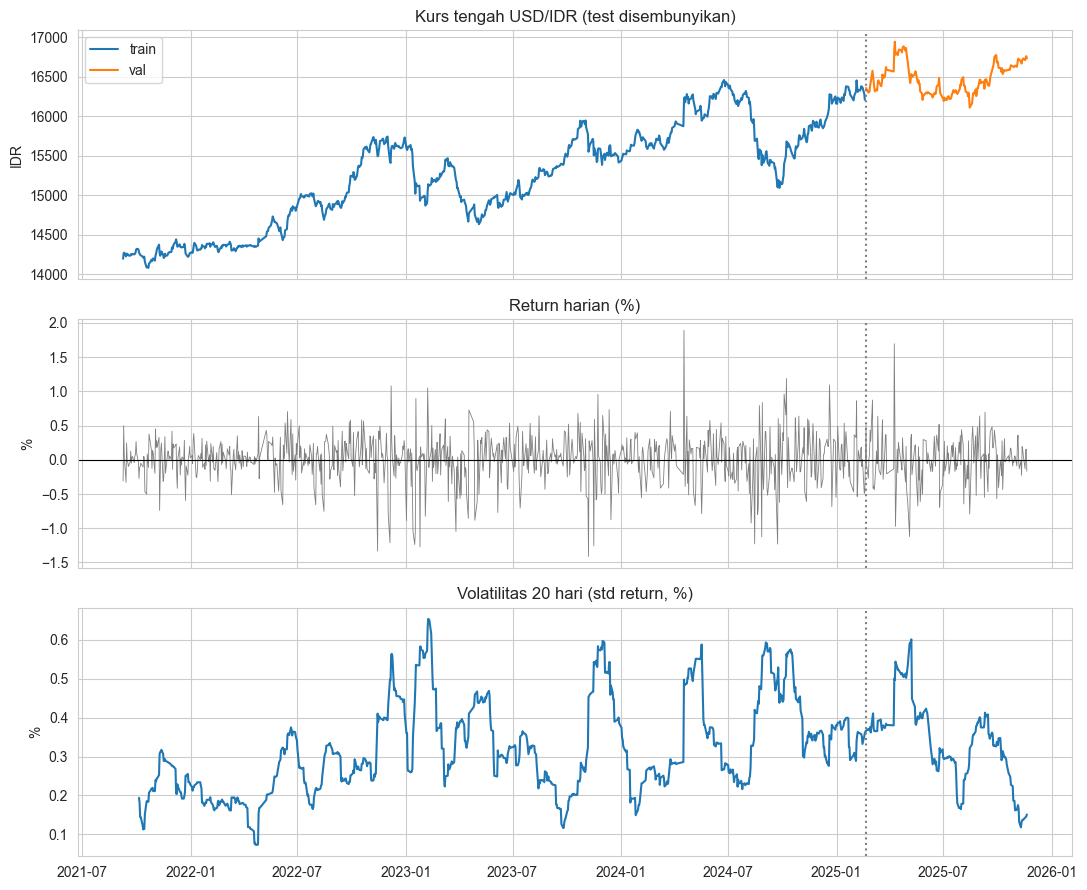

In [30]:
# Kurs tengah, return harian (%), dan volatilitas 20 hari (std return)
eda["vol20"] = eda["ret_pct"].rolling(20).std()

fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)

for name, part in eda.groupby("split", sort=False):
    axes[0].plot(part["Tanggal_dt"], part["kurs_mid"], label=name)
axes[0].set(title="Kurs tengah USD/IDR (test disembunyikan)", ylabel="IDR")
axes[0].legend(loc="upper left")

axes[1].plot(eda["Tanggal_dt"], eda["ret_pct"], lw=0.6, color="gray")
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set(title="Return harian (%)", ylabel="%")

axes[2].plot(eda["Tanggal_dt"], eda["vol20"])
axes[2].set(title="Volatilitas 20 hari (std return, %)", ylabel="%")

for ax in axes:
    ax.axvline(split_date, color="gray", ls=":")   # garis batas train | val
plt.tight_layout()
plt.show()

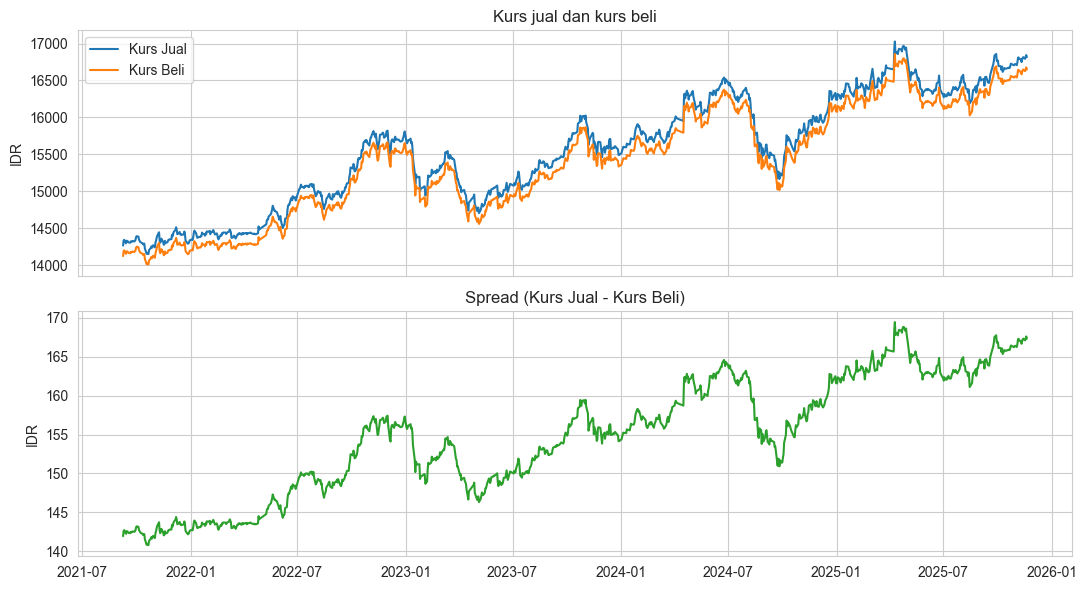

count    1014.00
mean      154.66
std         7.47
min       140.80
25%       148.98
50%       155.25
75%       162.00
max       169.44
Name: spread, dtype: float64
Korelasi Kurs Jual vs Kurs Beli: 1.0


In [31]:
# Spread kurs jual - kurs beli
eda["spread"] = eda["Kurs Jual"] - eda["Kurs Beli"]

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].plot(eda["Tanggal_dt"], eda["Kurs Jual"], label="Kurs Jual")
axes[0].plot(eda["Tanggal_dt"], eda["Kurs Beli"], label="Kurs Beli")
axes[0].set(title="Kurs jual dan kurs beli", ylabel="IDR")
axes[0].legend(loc="upper left")
axes[1].plot(eda["Tanggal_dt"], eda["spread"], color="C2")
axes[1].set(title="Spread (Kurs Jual - Kurs Beli)", ylabel="IDR")
plt.tight_layout()
plt.show()

print(eda["spread"].describe().round(2))
print("Korelasi Kurs Jual vs Kurs Beli:", round(eda["Kurs Jual"].corr(eda["Kurs Beli"]), 4))

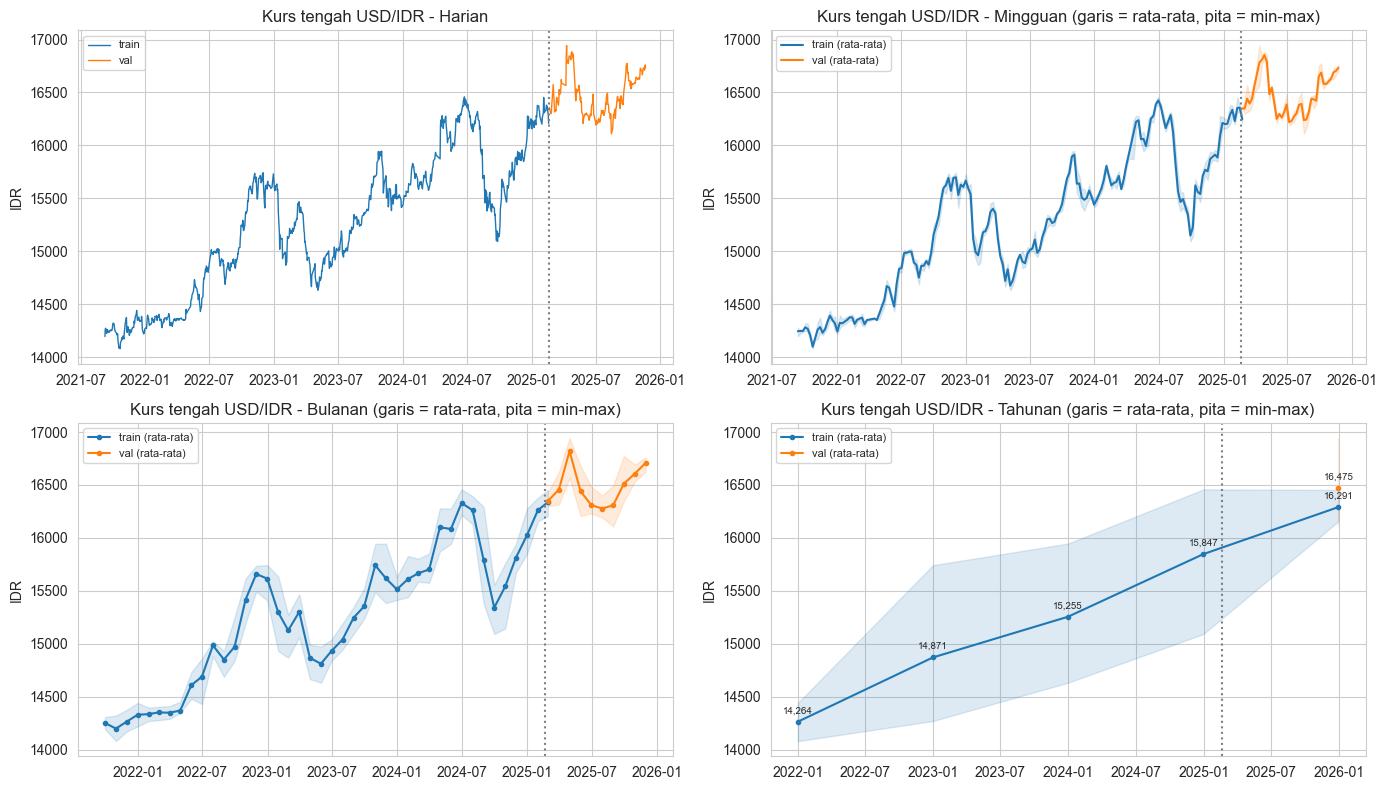

In [46]:
# Kurs tengah pada beberapa resolusi waktu: harian, mingguan, bulanan, tahunan
mid = eda.set_index("Tanggal_dt")["kurs_mid"]


# Kurs tengah pada beberapa resolusi waktu, train dan val dipisah warna (pita = min-max)
def resample_stats(series, new_rule, old_rule):
    # pandas >= 2.2 memakai "ME"/"YE", versi lama memakai "M"/"Y"
    try:
        grouped = series.resample(new_rule)
    except ValueError:
        grouped = series.resample(old_rule)
    return grouped.agg(["mean", "min", "max"]).dropna()


resolutions = [("Harian", None, None), ("Mingguan", "W", "W"), ("Bulanan", "ME", "M"), ("Tahunan", "YE", "Y")]
colors = {"train": "C0", "val": "C1"}

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, (title, new_rule, old_rule) in zip(axes.ravel(), resolutions):
    for name, part in eda.groupby("split", sort=False):
        s = part.set_index("Tanggal_dt")["kurs_mid"]
        if new_rule is None:
            ax.plot(s.index, s.values, color=colors[name], lw=1, label=name)
            continue
        st = resample_stats(s, new_rule, old_rule)
        ax.fill_between(st.index, st["min"], st["max"], color=colors[name], alpha=0.15)
        ax.plot(st.index, st["mean"], color=colors[name], lw=1.5,
                marker="o" if title in ("Bulanan", "Tahunan") else None, ms=3, label=f"{name} (rata-rata)")
        if title == "Tahunan":
            for t, v in st["mean"].items():
                ax.annotate(f"{v:,.0f}", (t, v), textcoords="offset points", xytext=(0, 6), ha="center", fontsize=7)
    ax.axvline(split_date, color="gray", ls=":")
    ax.set(title=f"Kurs tengah USD/IDR - {title}" + ("" if new_rule is None else " (garis = rata-rata, pita = min-max)"), ylabel="IDR")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 5.2 Distribusi Return Harian

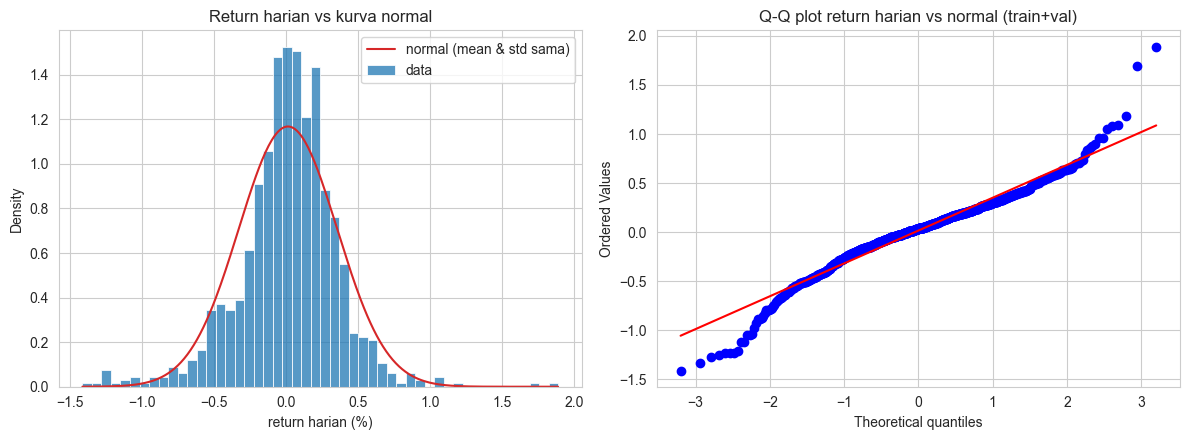

skew = -0.299 | excess kurtosis = 3.036
Jarque-Bera: stat = 399.15, p = 2.116e-87


In [47]:
# Histogram return vs kurva normal, dan Q-Q plot
r = eda["ret_pct"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.histplot(r, bins=50, stat="density", ax=axes[0], label="data")
x = np.linspace(r.min(), r.max(), 300)
axes[0].plot(x, stats.norm.pdf(x, r.mean(), r.std()), color="C3", label="normal (mean & std sama)")
axes[0].set(title="Return harian vs kurva normal", xlabel="return harian (%)")
axes[0].legend()

stats.probplot(r, dist="norm", plot=axes[1])
axes[1].set_title("Q-Q plot return harian vs normal (train+val)")
plt.tight_layout()
plt.show()

jb = stats.jarque_bera(r)
print(f"skew = {r.skew():.3f} | excess kurtosis = {r.kurt():.3f}")
print(f"Jarque-Bera: stat = {jb.statistic:.2f}, p = {jb.pvalue:.4g}")

## 5.3 Proporsi Hari Kurs Naik

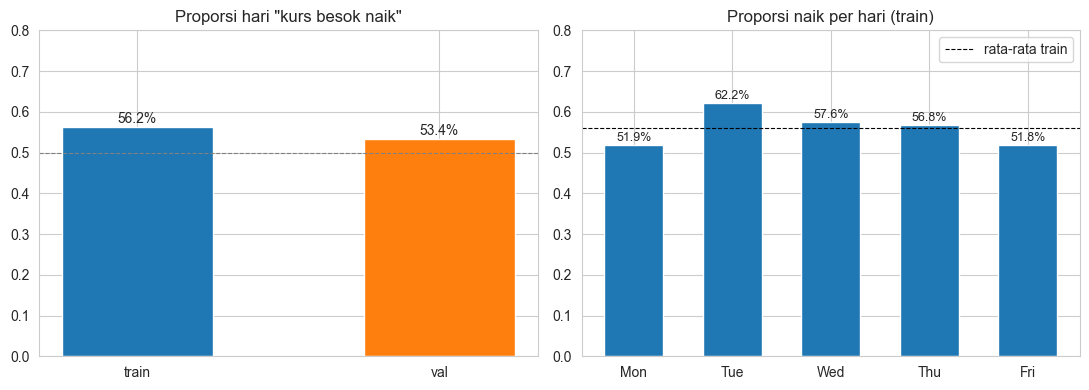

        n  naik
hari           
0     162    84
1     172   107
2     165    95
3     162    92
4     168    87
Uji binomial Senin vs rata-rata train: p = 0.303


In [48]:
def share_up(s):
    s = s[s != 0]            # nilai tepat 0 tidak punya arah, sama seperti DirAcc
    return (s > 0).mean()


fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# (a) proporsi hari "kurs besok naik" di train dan val
shares = {"train": share_up(train["target"]), "val": share_up(val["target"])}
axes[0].bar(list(shares), list(shares.values()), color=["C0", "C1"], width=0.5)
axes[0].axhline(0.5, color="gray", ls="--", lw=0.8)
for i, v in enumerate(shares.values()):
    axes[0].text(i, v + 0.01, f"{v:.1%}", ha="center")
axes[0].set(title='Proporsi hari "kurs besok naik"', ylim=(0, 0.8))

# (b) proporsi naik per hari dalam seminggu (train).
# Dikelompokkan menurut hari terjadinya return; return Senin dihitung terhadap Jumat (mencakup akhir pekan).
d = train[train["ret"] != 0].copy()
d["hari"] = d["Tanggal_dt"].dt.dayofweek
by_day = d.groupby("hari")["ret"].apply(lambda s: (s > 0).mean()).reindex(range(5))
overall = (d["ret"] > 0).mean()
axes[1].bar(["Mon", "Tue", "Wed", "Thu", "Fri"], by_day.values, width=0.6, color="C0")
axes[1].axhline(overall, color="black", ls="--", lw=0.8, label="rata-rata train")
for i, v in enumerate(by_day.values):
    axes[1].text(i, v + 0.01, f"{v:.1%}", ha="center", fontsize=9)
axes[1].set(title="Proporsi naik per hari (train)", ylim=(0, 0.8))
axes[1].legend()
plt.tight_layout()
plt.show()

# Jumlah hari per kelompok, supaya selisih antar hari bisa dinilai wajar atau tidak
cnt = d.groupby("hari")["ret"].agg(n="size", naik=lambda s: int((s > 0).sum()))
print(cnt)
p_senin = stats.binomtest(int(cnt.loc[0, "naik"]), int(cnt.loc[0, "n"]), p=overall).pvalue
print(f"Uji binomial Senin vs rata-rata train: p = {p_senin:.3f}")

## 5.4 Jumlah Berita per Hari

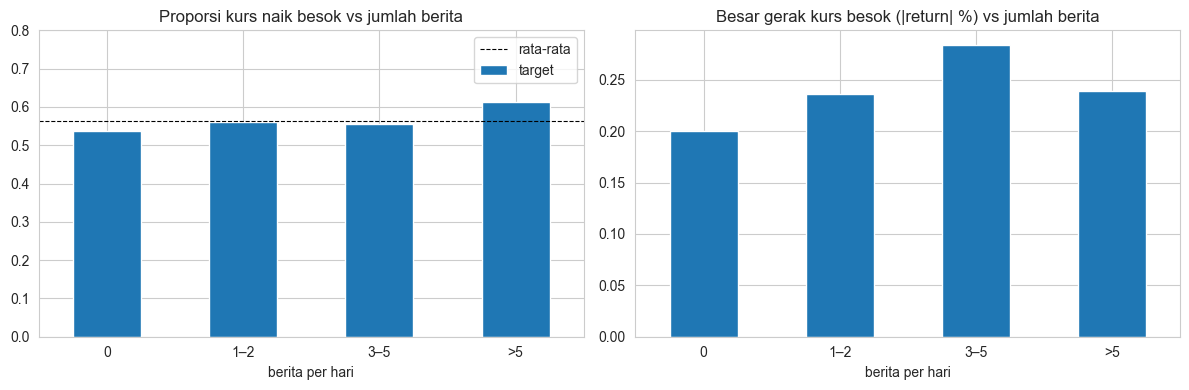

Jumlah hari per kelompok:
bin_berita
0      108
1–2    341
3–5    276
>5     111
Spearman news_count vs target: rho = 0.016, p = 0.638


In [35]:
# Hubungan jumlah berita hari ini dengan kurs besok (train)
bins = [-1, 0, 2, 5, np.inf]
labels = ["0", "1–2", "3–5", ">5"]

tr = train.copy()
tr["bin_berita"] = pd.cut(tr["news_count"], bins=bins, labels=labels)

nonzero = tr[tr["target"] != 0]
up_by_bin = nonzero.groupby("bin_berita", observed=False)["target"].apply(lambda s: (s > 0).mean())
mag_by_bin = tr.assign(abs_target_pct=tr["target"].abs() * 100).groupby("bin_berita", observed=False)["abs_target_pct"].mean()
n_per_bin = tr["bin_berita"].value_counts().reindex(labels)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
up_by_bin.plot.bar(ax=axes[0], rot=0)
axes[0].axhline(share_up(tr["target"]), color="black", ls="--", lw=0.8, label="rata-rata")
axes[0].set(title="Proporsi kurs naik besok vs jumlah berita", xlabel="berita per hari", ylim=(0, 0.8))
axes[0].legend()
mag_by_bin.plot.bar(ax=axes[1], rot=0)
axes[1].set(title="Besar gerak kurs besok (|return| %) vs jumlah berita", xlabel="berita per hari")
plt.tight_layout()
plt.show()

print("Jumlah hari per kelompok:")
print(n_per_bin.to_string())
rho, p = stats.spearmanr(tr["news_count"], tr["target"])
print(f"Spearman news_count vs target: rho = {rho:.3f}, p = {p:.3f}")

## 5.5 Korelasi

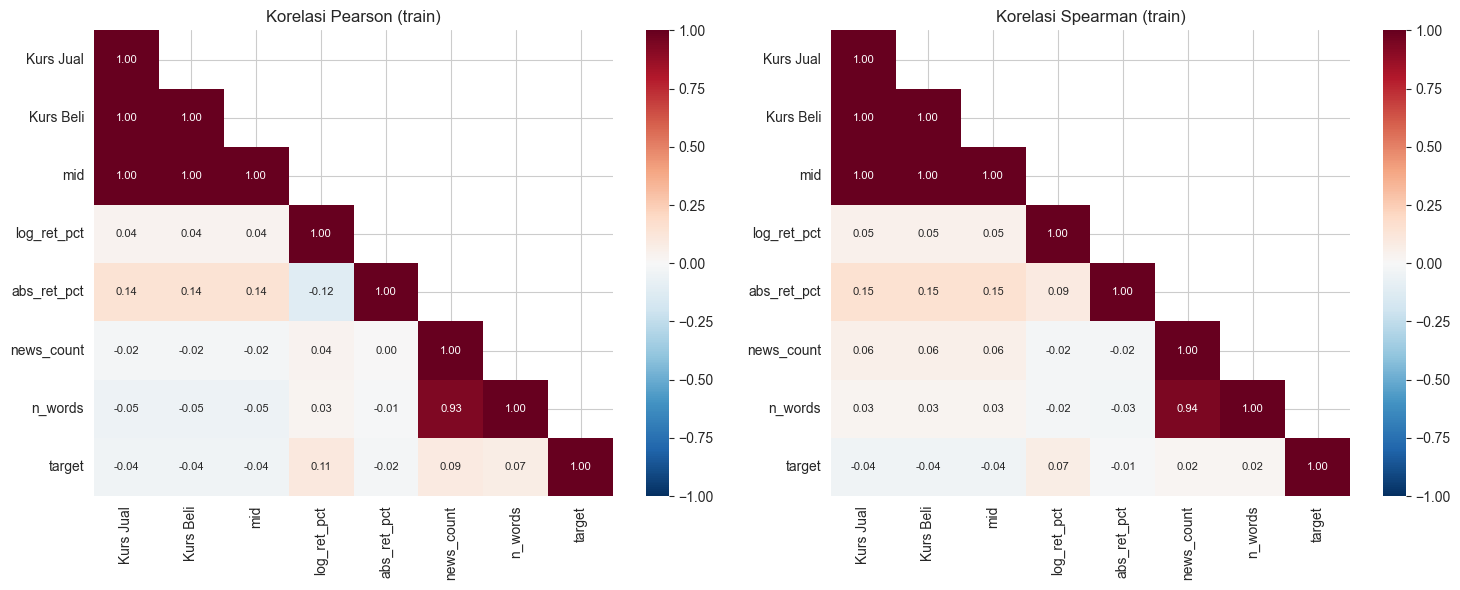

Korelasi Spearman dengan target:
Kurs Jual     -0.042
Kurs Beli     -0.042
mid           -0.042
log_ret_pct    0.072
abs_ret_pct   -0.009
news_count     0.016
n_words        0.017


In [36]:
# Korelasi Pearson dan Spearman pada train
words_per_day = news.groupby("aligned_trading_date")["full_text"].apply(lambda s: s.str.split().str.len().sum())

tr_corr = pd.DataFrame({
    "Kurs Jual": train["Kurs Jual"],
    "Kurs Beli": train["Kurs Beli"],
    "mid": train["kurs_mid"],
    "log_ret_pct": train["ret"] * 100,
    "abs_ret_pct": train["ret"].abs() * 100,
    "news_count": train["news_count"],
    "n_words": pd.to_datetime(train["Tanggal_dt"]).map(words_per_day).fillna(0),
    "target": train["target"],
})

mask = np.triu(np.ones((tr_corr.shape[1],) * 2, dtype=bool), k=1)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, method in zip(axes, ["pearson", "spearman"]):
    sns.heatmap(tr_corr.corr(method=method), mask=mask, annot=True, fmt=".2f", cmap="RdBu_r",
                vmin=-1, vmax=1, ax=ax, annot_kws={"size": 8})
    ax.set_title(f"Korelasi {method.capitalize()} (train)")
plt.tight_layout()
plt.show()

print("Korelasi Spearman dengan target:")
print(tr_corr.corr(method="spearman")["target"].drop("target").round(3).to_string())

## 6. Dataset Final

In [37]:
# Isi dataset final: tanggal, kurs_mid & ret (referensi), fitur kurs, fitur sentimen, dan target
final_cols = ["Tanggal_dt", "kurs_mid", "ret", *feat_ts, *feat_label, "target"]

final_train = train[final_cols].reset_index(drop=True)
final_val = val[final_cols].reset_index(drop=True)
final_test = test[final_cols].reset_index(drop=True)

for name, part in [("Train", final_train), ("Val", final_val), ("Test", final_test)]:
    assert part.isna().sum().sum() == 0, f"{name} masih ada NaN"
    print(f"{name:5}: {part.shape}")

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
for name, part in [("train", final_train), ("val", final_val), ("test", final_test)]:
    path = PROCESSED_DIR / f"{name}.csv"
    if path.exists():
        # File sudah ada: hanya dibandingkan, tidak ditimpa
        saved = pd.read_csv(path, parse_dates=["Tanggal_dt"])
        same = (
            list(saved.columns) == list(part.columns)
            and saved.shape == part.shape
            and (saved["Tanggal_dt"].values == part["Tanggal_dt"].values).all()
            and np.allclose(saved.drop(columns="Tanggal_dt"), part.drop(columns="Tanggal_dt"), rtol=1e-6, atol=1e-12)
        )
        print(f"{name}.csv sudah ada -> {'SAMA' if same else 'BEDA'} dengan hasil notebook (tidak ditimpa)")
    else:
        part.to_csv(path, index=False, date_format="%Y-%m-%d")
        print(f"{name}.csv belum ada -> ditulis")

Train: (836, 27)
Val  : (178, 27)
Test : (180, 27)
train.csv sudah ada -> SAMA dengan hasil notebook (tidak ditimpa)
val.csv sudah ada -> SAMA dengan hasil notebook (tidak ditimpa)
test.csv sudah ada -> SAMA dengan hasil notebook (tidak ditimpa)


## 7. Setup Modelling

In [38]:
pd.set_option("display.float_format", lambda x: f"{x:.6g}")

# Semua model pakai parameter default
MODELS = {
    "LinearRegression": lambda: LinearRegression(),
    "Ridge":            lambda: Ridge(),
    "Lasso":            lambda: Lasso(),
    "ElasticNet":       lambda: ElasticNet(),
    "BayesianRidge":    lambda: BayesianRidge(),
    "KNN":              lambda: KNeighborsRegressor(),
    "SVR":              lambda: SVR(),
    "DecisionTree":     lambda: DecisionTreeRegressor(random_state=SEED),
    "RandomForest":     lambda: RandomForestRegressor(random_state=SEED, n_jobs=-1),
    "ExtraTrees":       lambda: ExtraTreesRegressor(random_state=SEED, n_jobs=-1),
    "AdaBoost":         lambda: AdaBoostRegressor(random_state=SEED),
    "GradientBoosting": lambda: GradientBoostingRegressor(random_state=SEED),
}

# XGBoost dan LightGBM opsional, dilewati kalau belum terinstall
try:
    from xgboost import XGBRegressor
    MODELS["XGBoost"] = lambda: XGBRegressor(random_state=SEED, n_jobs=-1, verbosity=0)
except ImportError:
    print("xgboost belum terinstall, dilewati")

try:
    from lightgbm import LGBMRegressor
    MODELS["LightGBM"] = lambda: LGBMRegressor(random_state=SEED, n_jobs=-1, verbosity=-1)
except ImportError:
    print("lightgbm belum terinstall, dilewati")

METRICS = ["MAE", "MSE", "RMSE", "DirAcc"]


def evaluate(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mse = mean_squared_error(y_true, y_pred)

    # Arah tidak bisa ditentukan kalau target tepat 0, jadi baris itu dilewati
    nonzero = y_true != 0
    dir_acc = np.mean(np.sign(y_pred[nonzero]) == np.sign(y_true[nonzero])) if nonzero.any() else np.nan

    return {"MAE": mean_absolute_error(y_true, y_pred), "MSE": mse, "RMSE": np.sqrt(mse), "DirAcc": dir_acc}


y_tr, y_va, y_te = final_train["target"], final_val["target"], final_test["target"]


def prepare(cols):
    # Scaler di-fit di train saja, lalu dipakai juga untuk val & test
    scaler = StandardScaler().fit(final_train[cols])
    return (
        scaler.transform(final_train[cols]),
        scaler.transform(final_val[cols]),
        scaler.transform(final_test[cols]),
    )


def fit_eval(make_model, X_tr, X_va, X_te):
    # Latih di train, lalu evaluasi di val & test
    model = make_model().fit(X_tr, y_tr)
    results = {}
    for split, X, y in [("Val", X_va, y_va), ("Test", X_te, y_te)]:
        pred = model.predict(X)
        results[split] = {**evaluate(y, pred), "PredStd": float(np.std(pred))}
    return results


# Pembanding tanpa model: selalu tebak 0, atau tebak sama dengan return hari ini
eval_splits = [("Val", y_va, final_val), ("Test", y_te, final_test)]
naive = pd.DataFrame(
    [{"Baseline": "Prediksi 0", "Split": s, **evaluate(y, np.zeros(len(y)))} for s, y, _ in eval_splits]
    + [{"Baseline": "Return kemarin", "Split": s, **evaluate(y, part["ret"])} for s, y, part in eval_splits]
)

print(f"{len(MODELS)} model: {list(MODELS)}")
naive

14 model: ['LinearRegression', 'Ridge', 'Lasso', 'ElasticNet', 'BayesianRidge', 'KNN', 'SVR', 'DecisionTree', 'RandomForest', 'ExtraTrees', 'AdaBoost', 'GradientBoosting', 'XGBoost', 'LightGBM']


,Baseline,Split,MAE,MSE,RMSE,DirAcc
0,Prediksi 0,Val,0.00246991,1.14367e-05,0.00338182,0
1,Prediksi 0,Test,0.00220518,8.45542e-06,0.00290782,0
2,Return kemarin,Val,0.00346751,2.12584e-05,0.00461068,0.505682
3,Return kemarin,Test,0.00308416,1.58166e-05,0.00397701,0.545455


# II. Hasil Eksperimen Tugas 2

## 8. Baseline vs Baseline + NLP

- **Baseline**: fitur kurs saja (`kurs_lag1`–`kurs_lag5`, `kurs_roll_mean5`, `kurs_roll_std5`).
- **Baseline + NLP**: fitur kurs ditambah semua fitur sentimen (VADER, LM judul, LM isi).

Semua model dilatih di kedua set fitur, lalu hasilnya dibandingkan.

In [39]:
FEATURE_SETS = {
    "Baseline": feat_ts,
    "Baseline + NLP": feat_ts + feat_label,
}

rows = []
for set_name, cols in FEATURE_SETS.items():
    X_tr, X_va, X_te = prepare(cols)
    for model_name, make_model in MODELS.items():
        res = fit_eval(make_model, X_tr, X_va, X_te)
        for split in ("Val", "Test"):
            rows.append({
                "Model": model_name, "Set fitur": set_name,
                "n_fitur": len(cols), "Split": split, **res[split],
            })
    print(f"selesai: {set_name} ({len(cols)} fitur)")

results = pd.DataFrame(rows)

selesai: Baseline (7 fitur)
selesai: Baseline + NLP (23 fitur)


In [40]:
set_order = list(FEATURE_SETS)

# Ringkasan: rata-rata metrik semua model untuk tiap set fitur
summary_index = pd.MultiIndex.from_product([["Val", "Test"], set_order], names=["Split", "Set fitur"])
summary = results.groupby(["Split", "Set fitur"])[METRICS].mean().reindex(summary_index)
print("Rata-rata metrik semua model per set fitur:")
display(summary)

# Detail per model untuk tiap metrik
for split in ("Val", "Test"):
    for metric in METRICS:
        table = (
            results[results["Split"] == split]
            .pivot(index="Model", columns="Set fitur", values=metric)[set_order]
            .reindex(list(MODELS))
        )
        print(f"\n=== {metric} | {split} ===")
        display(table)

Rata-rata metrik semua model per set fitur:


MAE         MSE       RMSE   DirAcc
Split Set fitur                                                
Val   Baseline       0.00272292 1.31602e-05 0.00361236 0.502029
      Baseline + NLP 0.00278833 1.40712e-05 0.00373079 0.484578
Test  Baseline        0.0024556 1.01535e-05 0.00316759 0.483766
      Baseline + NLP 0.00251708 1.09119e-05 0.00327346 0.518669


=== MAE | Val ===


Set fitur,Baseline,Baseline + NLP
Model,,
LinearRegression,0.00252672,0.00266398
Ridge,0.00251092,0.00265096
Lasso,0.00246464,0.00246464
ElasticNet,0.00246464,0.00246464
BayesianRidge,0.00250102,0.00257518
KNN,0.00284737,0.00278374
SVR,0.00310973,0.00310973
DecisionTree,0.00358013,0.00348397
RandomForest,0.00260867,0.00267258



=== MSE | Val ===


Set fitur,Baseline,Baseline + NLP
Model,,
LinearRegression,1.15704e-05,1.22903e-05
Ridge,1.15099e-05,1.2228e-05
Lasso,1.14207e-05,1.14207e-05
ElasticNet,1.14207e-05,1.14207e-05
BayesianRidge,1.14832e-05,1.19602e-05
KNN,1.34228e-05,1.39608e-05
SVR,1.65624e-05,1.65624e-05
DecisionTree,2.13416e-05,2.39641e-05
RandomForest,1.19681e-05,1.2639e-05


... (8 outputs left out)


=== RMSE | Test ===


Set fitur,Baseline,Baseline + NLP
Model,,
LinearRegression,0.00299457,0.00292497
Ridge,0.00298868,0.00292402
Lasso,0.00289376,0.00289376
ElasticNet,0.00289376,0.00289376
BayesianRidge,0.00298408,0.00293766
KNN,0.00298064,0.00353394
SVR,0.00355238,0.00355238
DecisionTree,0.00419307,0.00464153
RandomForest,0.0030043,0.00320554



=== DirAcc | Test ===


Set fitur,Baseline,Baseline + NLP
Model,,
LinearRegression,0.477273,0.585227
Ridge,0.4375,0.573864
Lasso,0.590909,0.590909
ElasticNet,0.590909,0.590909
BayesianRidge,0.414773,0.511364
KNN,0.528409,0.454545
SVR,0.590909,0.590909
DecisionTree,0.426136,0.539773
RandomForest,0.420455,0.414773


In [41]:
# Set fitur yang lebih bagus untuk tiap model, dipilih dari RMSE validation (nilai test hanya dilaporkan)
val_res = results[results["Split"] == "Val"]
test_res = results[results["Split"] == "Test"].set_index(["Model", "Set fitur"])
best_rows = val_res.loc[val_res.groupby("Model")["RMSE"].idxmin()]

best_per_model = (
    best_rows.set_index("Model")[["Set fitur", "n_fitur", "RMSE"]]
    .rename(columns={"RMSE": "Val RMSE"})
)
for metric in METRICS:
    best_per_model[f"Test {metric}"] = [
        test_res.loc[(model, set_name), metric]
        for model, set_name in zip(best_per_model.index, best_per_model["Set fitur"])
    ]
best_per_model = best_per_model.reindex(list(MODELS)).sort_values("Val RMSE")

print("Set fitur terbaik per model:")
display(best_per_model)

Set fitur terbaik per model:


,Set fitur,n_fitur,Val RMSE,Test MAE,Test MSE,Test RMSE,Test DirAcc
Model,,,,,,,
Lasso,Baseline,7,0.00337945,0.0021809,8.37383e-06,0.00289376,0.590909
ElasticNet,Baseline,7,0.00337945,0.0021809,8.37383e-06,0.00289376,0.590909
BayesianRidge,Baseline,7,0.00338869,0.00229396,8.90476e-06,0.00298408,0.414773
Ridge,Baseline,7,0.00339263,0.00229696,8.93223e-06,0.00298868,0.4375
LinearRegression,Baseline,7,0.00340153,0.00230292,8.96746e-06,0.00299457,0.477273
AdaBoost,Baseline,7,0.00344297,0.00234884,9.07439e-06,0.00301237,0.477273
RandomForest,Baseline,7,0.00345949,0.00232296,9.02585e-06,0.0030043,0.420455
ExtraTrees,Baseline,7,0.00348428,0.00230994,8.99494e-06,0.00299916,0.431818
LightGBM,Baseline,7,0.0035689,0.00241147,9.71604e-06,0.00311706,0.488636


## 9. Model Gabungan + Ekstraksi Fitur (TF-IDF + SVD)

Teks berita sehari digabung jadi satu dokumen, divektorisasi dengan TF-IDF, lalu direduksi ke 100 komponen dengan TruncatedSVD.
TF-IDF dan SVD **di-fit di train saja**. Hari tanpa berita mendapat vektor nol.
Fitur: kurs (7) + sentimen (16) + SVD (100).

In [42]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD

N_SVD = 100
feat_svd = [f"svd_{i}" for i in range(N_SVD)]

# Teks harian: semua berita di hari trading yang sama digabung jadi satu dokumen
daily_text = news.groupby("aligned_trading_date")["lower_text"].apply(" ".join)


def text_of(df):
    return pd.to_datetime(df["Tanggal_dt"]).map(daily_text).fillna("")


txt_tr, txt_va, txt_te = text_of(final_train), text_of(final_val), text_of(final_test)

# Fit di train saja (hari tanpa berita tidak ikut membentuk kosakata)
tfidf = TfidfVectorizer(max_features=2000, ngram_range=(1, 2), min_df=5)
tfidf.fit(txt_tr[txt_tr.str.len() > 0])
svd = TruncatedSVD(n_components=N_SVD, random_state=SEED)
svd.fit(tfidf.transform(txt_tr))
print(f"Kosakata TF-IDF: {len(tfidf.vocabulary_)} | varians dijelaskan SVD: {svd.explained_variance_ratio_.sum():.1%}")


def svd_frame(txt):
    return pd.DataFrame(svd.transform(tfidf.transform(txt)), columns=feat_svd)


ext_tr = pd.concat([final_train[feat_ts + feat_label].reset_index(drop=True), svd_frame(txt_tr)], axis=1)
ext_va = pd.concat([final_val[feat_ts + feat_label].reset_index(drop=True), svd_frame(txt_va)], axis=1)
ext_te = pd.concat([final_test[feat_ts + feat_label].reset_index(drop=True), svd_frame(txt_te)], axis=1)
print("Bentuk fitur:", ext_tr.shape, ext_va.shape, ext_te.shape)

Kosakata TF-IDF: 2000 | varians dijelaskan SVD: 70.3%
Bentuk fitur: (836, 123) (178, 123) (180, 123)


In [43]:
SET_SVD = "Baseline + NLP + SVD"

# Scaler di-fit di train saja
scaler_ext = StandardScaler().fit(ext_tr)
X_tr, X_va, X_te = scaler_ext.transform(ext_tr), scaler_ext.transform(ext_va), scaler_ext.transform(ext_te)

rows_svd = []
for model_name, make_model in MODELS.items():
    res = fit_eval(make_model, X_tr, X_va, X_te)
    for split in ("Val", "Test"):
        rows_svd.append({"Model": model_name, "Set fitur": SET_SVD, "n_fitur": ext_tr.shape[1], "Split": split, **res[split]})

results_all = pd.concat([results, pd.DataFrame(rows_svd)], ignore_index=True)
sets_all = [*FEATURE_SETS, SET_SVD]

# Rata-rata semua model per set fitur
idx = pd.MultiIndex.from_product([["Val", "Test"], sets_all], names=["Split", "Set fitur"])
print("Rata-rata metrik semua model per set fitur:")
display(results_all.groupby(["Split", "Set fitur"])[METRICS].mean().reindex(idx))

# ElasticNet (model yang dibandingkan di slide), lengkap dengan PredStd
print("ElasticNet pada tiap set fitur:")
display(
    results_all[results_all["Model"] == "ElasticNet"]
    .set_index(["Split", "Set fitur"])[["n_fitur", *METRICS, "PredStd"]]
    .reindex(idx)
)

Rata-rata metrik semua model per set fitur:


MAE         MSE       RMSE   DirAcc
Split Set fitur                                                      
Val   Baseline             0.00272292 1.31602e-05 0.00361236 0.502029
      Baseline + NLP       0.00278833 1.40712e-05 0.00373079 0.484578
      Baseline + NLP + SVD 0.00277485 1.38159e-05  0.0036935 0.504464
Test  Baseline              0.0024556 1.01535e-05 0.00316759 0.483766
      Baseline + NLP       0.00251708 1.09119e-05 0.00327346 0.518669
      Baseline + NLP + SVD 0.00249556 1.09755e-05  0.0032828 0.517045

ElasticNet pada tiap set fitur:


n_fitur        MAE         MSE       RMSE  \
Split Set fitur                                                         
Val   Baseline                    7 0.00246464 1.14207e-05 0.00337945   
      Baseline + NLP             23 0.00246464 1.14207e-05 0.00337945   
      Baseline + NLP + SVD      123 0.00246464 1.14207e-05 0.00337945   
Test  Baseline                    7  0.0021809 8.37383e-06 0.00289376   
      Baseline + NLP             23  0.0021809 8.37383e-06 0.00289376   
      Baseline + NLP + SVD      123  0.0021809 8.37383e-06 0.00289376   

                             DirAcc     PredStd  
Split Set fitur                                  
Val   Baseline             0.534091 2.71051e-20  
      Baseline + NLP       0.534091 2.71051e-20  
      Baseline + NLP + SVD 0.534091 2.71051e-20  
Test  Baseline             0.590909 2.71051e-20  
      Baseline + NLP       0.590909 2.71051e-20  
      Baseline + NLP + SVD 0.590909 2.71051e-20

## 10. Ringkasan Kelompok Fitur

In [44]:
# Kelompok fitur yang dipakai di notebook ini
group_info = [
    ("Kurs (baseline)", "Level dan dinamika kurs", feat_ts,
     "lag 1-5 kurs tengah, rata-rata dan std rolling 5 hari"),
    ("VADER", "Nada umum judul", LABEL_GROUPS.get("VADER", []),
     "mean, min, max, std, rasio positif dan negatif per hari"),
    ("LM judul", "Nada judul dalam konteks keuangan", LABEL_GROUPS.get("LM judul", []),
     "rata-rata harian skor LM"),
    ("LM isi", "Nada keseluruhan artikel dalam konteks keuangan", LABEL_GROUPS.get("LM isi", []),
     "rata-rata harian skor LM"),
    ("SVD (TF-IDF)", "Konten dan topik berita", feat_svd,
     "teks harian digabung, TF-IDF, lalu TruncatedSVD"),
]
pd.DataFrame([
    {"Kelompok": g, "Dimensi yang ditangkap": dim, "Jumlah fitur": len(cols), "Agregasi harian": agg}
    for g, dim, cols, agg in group_info
])

,Kelompok,Dimensi yang ditangkap,Jumlah fitur,Agregasi harian
0,Kurs (baseline),Level dan dinamika kurs,7,"lag 1-5 kurs tengah, rata-rata dan std rolling 5 hari"
1,VADER,Nada umum judul,6,"mean, min, max, std, rasio positif dan negatif per hari"
2,LM judul,Nada judul dalam konteks keuangan,5,rata-rata harian skor LM
3,LM isi,Nada keseluruhan artikel dalam konteks keuangan,5,rata-rata harian skor LM
4,SVD (TF-IDF),Konten dan topik berita,100,"teks harian digabung, TF-IDF, lalu TruncatedSVD"


## 11. Ablasi Kombinasi Label

Semua kombinasi sumber label (VADER, LM judul, LM isi) ditambahkan ke fitur kurs. Dengan 3 sumber ada 8 kombinasi.
Angka adalah **rata-rata semua model** pada tiap kombinasi.

In [45]:
from itertools import combinations

group_names = list(LABEL_GROUPS)
ablation_sets = {}
for r_ in range(len(group_names) + 1):
    for combo in combinations(group_names, r_):
        name = " + ".join(combo) if combo else "Tanpa labelling"
        ablation_sets[name] = feat_ts + [c for g in combo for c in LABEL_GROUPS[g]]

abl_rows = []
for set_name, cols in ablation_sets.items():
    X_tr, X_va, X_te = prepare(cols)
    for model_name, make_model in MODELS.items():
        res = fit_eval(make_model, X_tr, X_va, X_te)
        for split in ("Val", "Test"):
            abl_rows.append({"Model": model_name, "Set fitur": set_name, "n_fitur": len(cols), "Split": split, **res[split]})
ablasi = pd.DataFrame(abl_rows)

abl_table = (
    ablasi.groupby(["Set fitur", "Split"])["RMSE"].mean().unstack("Split")[["Val", "Test"]]
    .rename(columns={"Val": "Val RMSE", "Test": "Test RMSE"})
    .reindex(list(ablation_sets))
)
abl_table.insert(0, "n_fitur", [len(c) for c in ablation_sets.values()])
abl_table

Split,n_fitur,Val RMSE,Test RMSE
Set fitur,,,
Tanpa labelling,7,0.00361236,0.00316759
VADER,13,0.00372723,0.00328604
LM judul,12,0.00361414,0.00318017
LM isi,12,0.00375316,0.00329762
VADER + LM judul,18,0.00370111,0.00332238
VADER + LM isi,18,0.00372537,0.00332559
LM judul + LM isi,17,0.00369316,0.00327216
VADER + LM judul + LM isi,23,0.00373079,0.00327346


# III. Analisis Tugas 3

## 11. Studi Ablasi (Model A/B/C)

## 12. Feature Importance

## 13. Distribusi Error